# 问题2：官方相关矩阵、全部50维Top-3与化学证据

这是结果复查Notebook，不是完整训练流程。完整计算入口为 scripts/run_review.py。

In [1]:
from pathlib import Path
import os
import pandas as pd
from IPython.display import display, Image
OUT=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/'q1_metrics.csv').is_file()), None)
if OUT is None:
    ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/'scripts/run_review.py').is_file()), None)
    if ROOT is None: raise FileNotFoundError('请从项目目录或输出目录启动Notebook')
    OUT=Path(os.environ.get('MATHORCUP_OUTPUT',str(ROOT/'results' if (ROOT/'results').is_dir() else ROOT/'outputs/competition_candidate_v3')))
pd.set_option('display.max_rows',160)
pd.set_option('display.max_columns',25)

## 说明

附件2实际匹配Spearman而非题面所称Pearson；选取218项单项测量候选，其他指标不作为“化合物”。bootstrap=200，频率衡量排名稳定性，不代表因果概率。全部50维输出，超出Aroma/Flavour的20维作补充。

In [2]:
display(pd.read_csv(OUT/'q2_official_correlation_type_check.csv')); e=pd.read_csv(OUT/'q2_top3_all50_evidence.csv'); assert len(e)==150 and e.groupby('target').size().eq(3).all(); display(e); display(pd.read_csv(OUT/'q2_method_sensitivity.csv'))

,method,n,mean_abs_difference,max_abs_difference
0,pearson,26565,8.768353e-02,1.123426e+00
1,spearman,26565,1.590110e-16,6.661338e-16


,target,rank,field,chemical_name,rho,n,bootstrap_frequency,bootstrap_rho_low,bootstrap_rho_high,style_adjusted_rho,direction_agrees,origin,unit,off_flavors,family_hint,interpretation,chemical_plausibility,ranking_stable_80pct,candidate_class,documented_compound_class
0,A_malt_all,1,acetaldehyde,Acetaldehyde,0.361211,250,0.600,0.235098,0.462787,0.031976,True,Yeast,mg/L,"pungent, rotten-apples, green apple",名称词根提示尚未核实；不作为化合物类别证据,关联候选；同源代谢和风格混杂均可能解释，不能推断单体因果,麦芽目标但附件来源为Yeast，可能是共变代理，缺乏直接麦芽机制证据,False,exploratory_association,NaN
1,A_malt_all,2,methylpyrazine,Methylpyrazine,0.356057,238,0.515,0.240074,0.467147,0.166346,True,Malt,mg/L,NaN,名称词根提示尚未核实；不作为化合物类别证据,关联候选；同源代谢和风格混杂均可能解释，不能推断单体因果,Malt来源标注与目标类别相符，仅是机制线索，不是已证实致味机制,False,exploratory_association,NaN
2,A_malt_all,3,ethanol..v.v.,Ethanol,0.334995,250,0.410,0.214547,0.436633,-0.102729,False,Yeast,v/v,NaN,名称词根提示尚未核实；不作为化合物类别证据,关联候选；同源代谢和风格混杂均可能解释，不能推断单体因果,麦芽目标但附件来源为Yeast，可能是共变代理，缺乏直接麦芽机制证据；控制风格后方向反转，证...,False,style_direction_reversal,NaN
3,A_malt_grain,1,terpinen.4.ol,Terpinen-4-ol,-0.264539,250,0.600,-0.354571,-0.153513,-0.224122,True,Spices,NaN,NaN,名称词根提示尚未核实；不作为化合物类别证据,关联候选；同源代谢和风格混杂均可能解释，不能推断单体因果,麦芽目标但附件来源为Spices，可能是共变代理，缺乏直接麦芽机制证据,False,exploratory_association,NaN
4,A_malt_grain,2,beta.phellandrene,Beta-phellandrene,-0.248036,250,0.485,-0.356293,-0.143786,-0.181238,True,Hops,NaN,NaN,名称词根提示尚未核实；不作为化合物类别证据,关联候选；同源代谢和风格混杂均可能解释，不能推断单体因果,麦芽目标但附件来源为Hops，可能是共变代理，缺乏直接麦芽机制证据；入选频率低于50%，排序较弱,False,exploratory_association,NaN
5,A_malt_grain,3,isoborneol,Isoborneol,-0.224753,250,0.175,-0.342668,-0.115776,-0.194381,True,Others,NaN,NaN,名称词根提示尚未核实；不作为化合物类别证据,关联候选；同源代谢和风格混杂均可能解释，不能推断单体因果,麦芽目标但附件来源为Others，可能是共变代理，缺乏直接麦芽机制证据；入选频率低于50%，...,False,exploratory_association,NaN
6,A_malt_bread,1,glycerol,Glycerol,0.266636,250,0.330,0.163988,0.382839,0.042343,True,Yeast,g/L,NaN,名称词根提示尚未核实；不作为化合物类别证据,关联候选；同源代谢和风格混杂均可能解释，不能推断单体因果,麦芽目标但附件来源为Yeast，可能是共变代理，缺乏直接麦芽机制证据；入选频率低于50%，排序较弱,False,exploratory_association,NaN
7,A_malt_bread,2,ethanol..v.v.,Ethanol,0.259942,250,0.315,0.149953,0.384892,-0.062269,False,Yeast,v/v,NaN,名称词根提示尚未核实；不作为化合物类别证据,关联候选；同源代谢和风格混杂均可能解释，不能推断单体因果,麦芽目标但附件来源为Yeast，可能是共变代理，缺乏直接麦芽机制证据；控制风格后方向反转，证...,False,style_direction_reversal,NaN
8,A_malt_bread,3,terpinen.4.ol,Terpinen-4-ol,-0.250225,250,0.235,-0.355477,-0.110138,-0.196772,True,Spices,NaN,NaN,名称词根提示尚未核实；不作为化合物类别证据,关联候选；同源代谢和风格混杂均可能解释，不能推断单体因果,麦芽目标但附件来源为Spices，可能是共变代理，缺乏直接麦芽机制证据；入选频率低于50%，...,False,exploratory_association,NaN
9,A_malt_cara,1,acetaldehyde,Acetaldehyde,0.350157,250,0.640,0.222886,0.469968,0.014869,True,Yeast,mg/L,"pungent, rotten-apples, green apple",名称词根提示尚未核实；不作为化合物类别证据,关联候选；同源代谢和风格混杂均可能解释，不能推断单体因果,麦芽目标但附件来源为Yeast，可能是共变代理，缺乏直接麦芽机制证据,False,exploratory_association,NaN


,target,jaccard_pearson_spearman
0,A_malt_all,0.2
1,A_malt_grain,0.0
2,A_malt_bread,0.0
3,A_malt_cara,0.2
4,A_malt_burn,0.0
5,A_hops_all,0.5
6,A_hops_citrus,0.0
7,A_hops_tropical,0.2
8,A_hops_noble,0.5
9,A_hops_woody,0.5


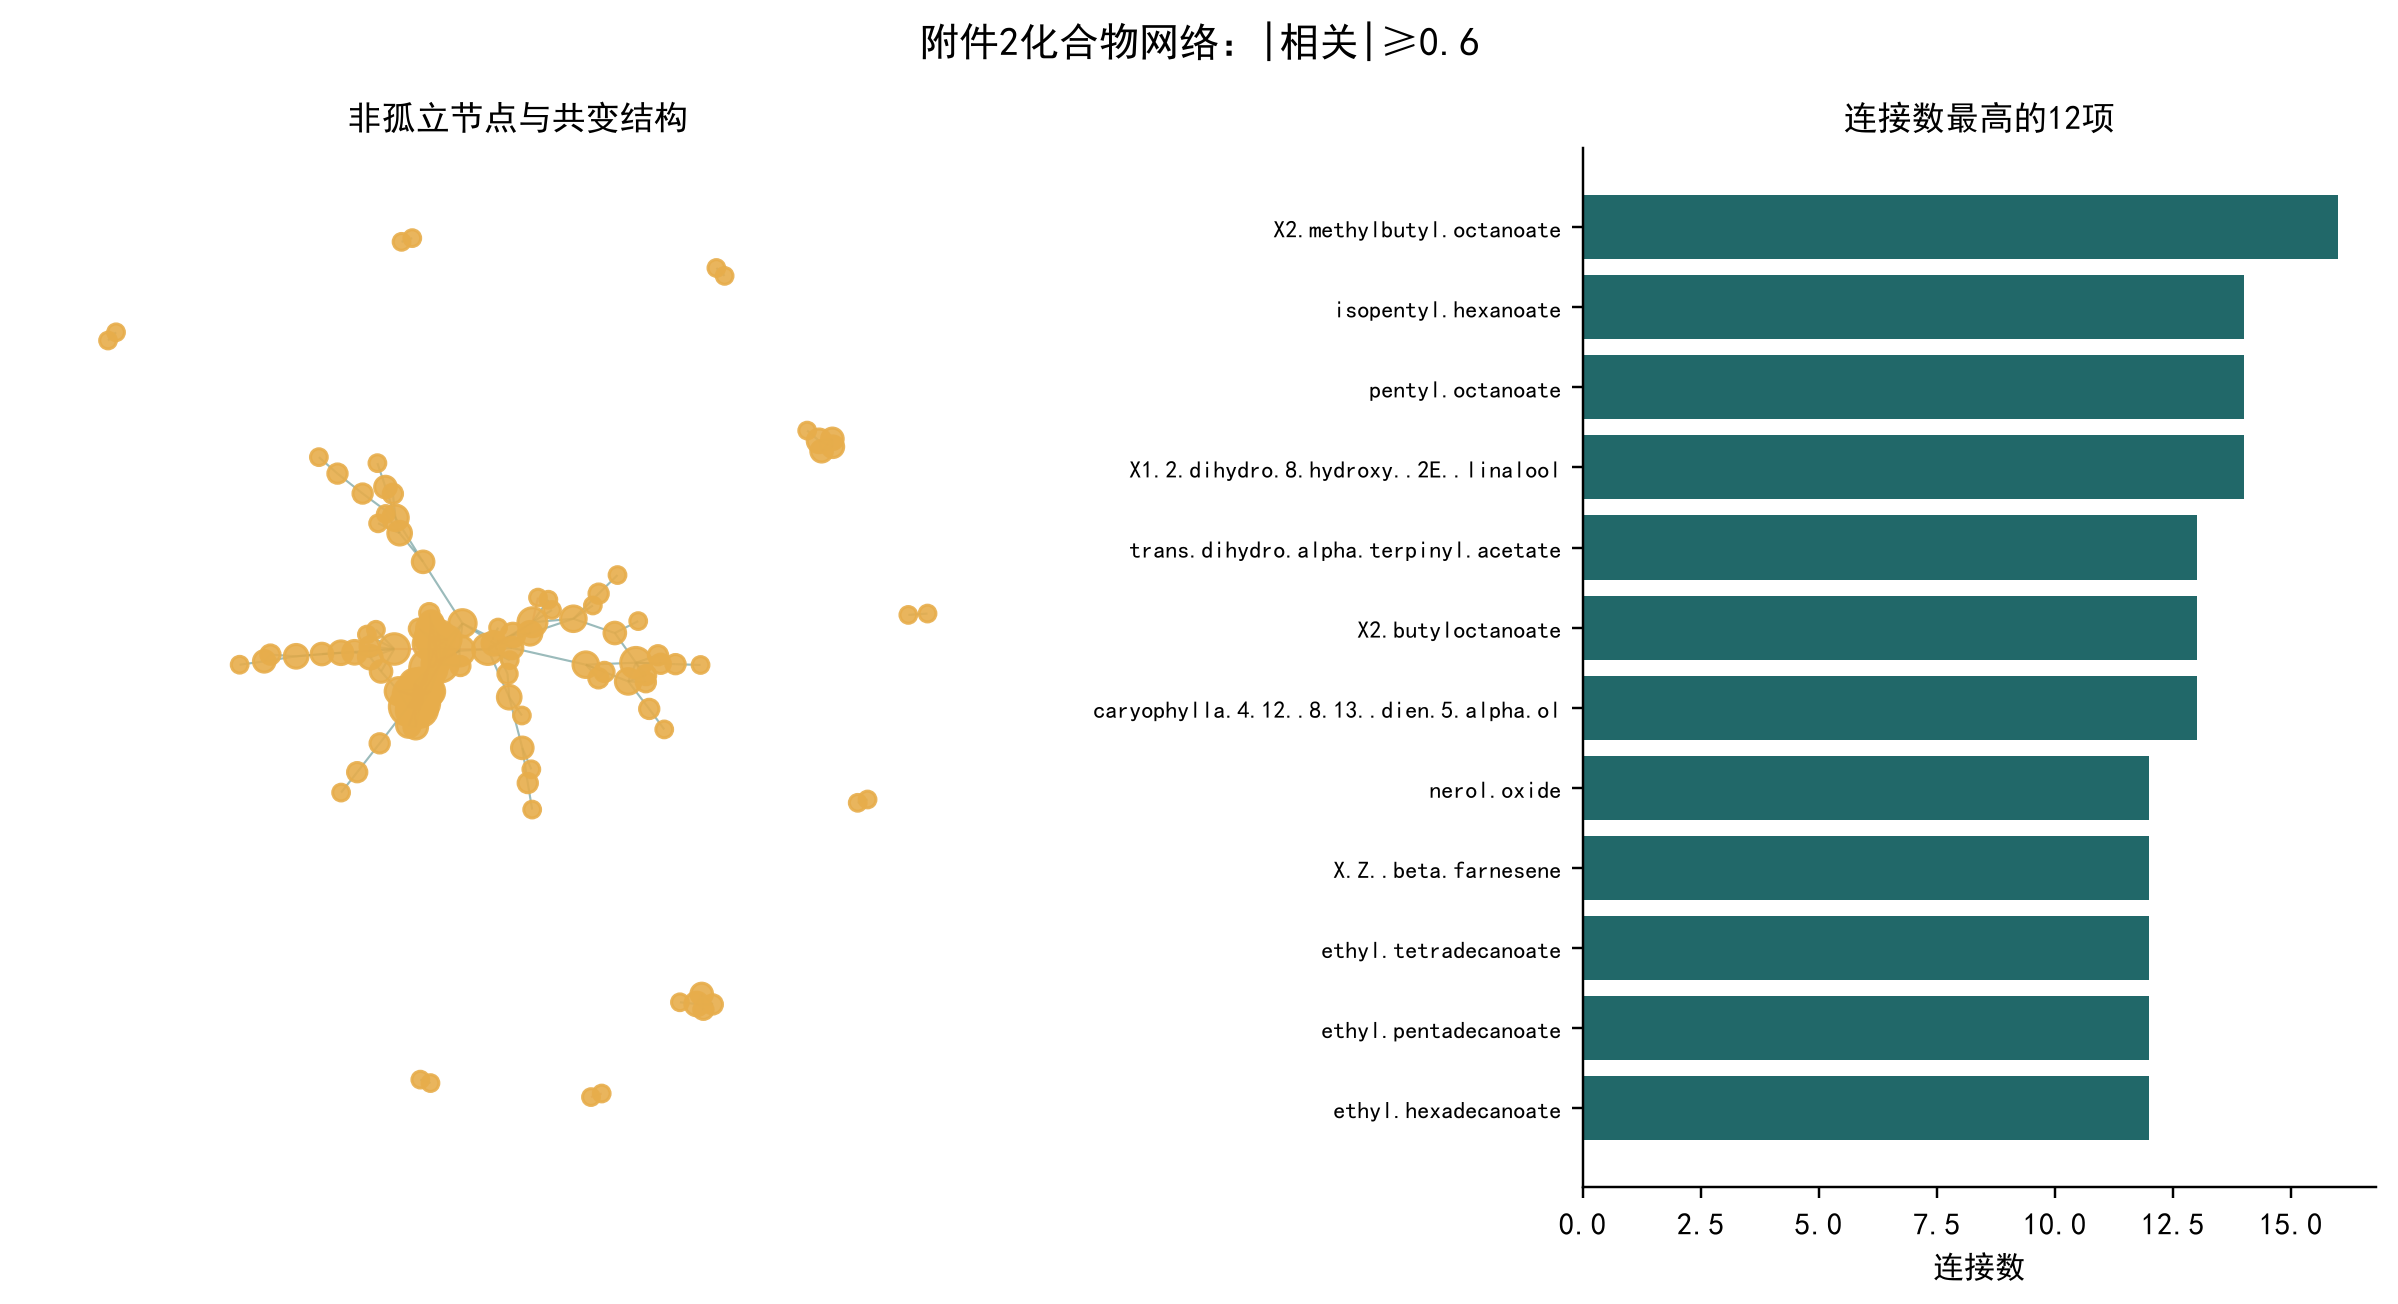

In [3]:
display(Image(filename=str(OUT/'figures/03_compound_network.png')))